# SignVerse - Deep Learning Module 1: Communication Engine (WLASL-300 Benchmark)
**Self-Contained Interactive Notebook: Scaled 300-Class Model Training, Sentence-Boundary Webcam Recognition & Enhanced 3D Avatar Rendering**

---
### Notebook Structure (100% Self-Contained):
1. **Environment Setup & Imports**: Import TensorFlow, MediaPipe, OpenCV, NumPy, Matplotlib & Pyttsx3.
2. **Wrist-Normalized MediaPipe Landmark Extractor Class**: Code for 3D position-invariant keypoint extraction.
3. **Dataset Loading & Augmentation**: Load WLASL-300 landmark vectors (`2,660` videos, `300` classes) and apply scale jitter + Gaussian noise.
4. **Train, Validation & Test Dataset Splitting**: 70% Train, 15% Validation, 15% Testing.
5. **Deep Conv1D + Bidirectional LSTM Model Architecture**: 300-class spatial-temporal neural network.
6. **Model Training & Epoch Monitoring**: Train model with EarlyStopping, Checkpoint & LR reduction.
7. **Evaluation Metrics & Plot Visualizations**: Plot Accuracy/Loss curves.
8. **Real-Time Webcam Recognition with Sentence Boundaries**: Live recognition with `SPACE` key to end sentence & auto-narrate.
9. **Enhanced 3D Avatar Skeleton Translator**: Render full arm & hand skeleton animations for typed text.


## 1. Environment Setup & Import Dependencies


In [2]:
import os
import json
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import mediapipe as mp
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, BatchNormalization, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

try:
    import pyttsx3
    TTS_AVAILABLE = True
except ImportError:
    TTS_AVAILABLE = False

print("[OK] TensorFlow Version:", tf.__version__)
print("[OK] MediaPipe Version:", mp.__version__)
print("[OK] GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)
print("[OK] Text-To-Speech (TTS) Available:", TTS_AVAILABLE)


[OK] TensorFlow Version: 2.15.0
[OK] MediaPipe Version: 0.10.14
[OK] GPU Available: False
[OK] Text-To-Speech (TTS) Available: True


## 2. MediaPipe Landmark Extractor (Wrist Position Normalization Code)
Extracts 21 keypoints per hand (X, Y, Z coordinates). Subtracts wrist position (`pts - wrist`) to make landmark features 100% invariant to camera position.

In [3]:
class NotebookMediaPipeLandmarkExtractor:
    def __init__(self, static_image_mode=False, max_num_hands=2, min_detection_confidence=0.5):
        self.mp_hands = mp.solutions.hands
        self.mp_drawing = mp.solutions.drawing_utils
        self.hands = self.mp_hands.Hands(
            static_image_mode=static_image_mode,
            max_num_hands=max_num_hands,
            min_detection_confidence=min_detection_confidence,
            min_tracking_confidence=0.5
        )

    def _normalize_hand(self, pts):
        # Subtract wrist landmark position (landmark index 0) for position invariance
        wrist = pts[0, :].copy()
        pts = pts - wrist
        max_val = np.max(np.abs(pts))
        if max_val > 0:
            pts = pts / max_val
        return pts

    def extract_landmarks(self, image):
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        results = self.hands.process(image_rgb)
        
        landmarks_vector = np.zeros(2 * 21 * 3, dtype=np.float32)
        annotated_image = image.copy()
        detected_count = 0
        
        if results.multi_hand_landmarks and results.multi_handedness:
            detected_count = len(results.multi_hand_landmarks)
            for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):
                label = handedness.classification[0].label # Left or Right
                self.mp_drawing.draw_landmarks(annotated_image, hand_landmarks, self.mp_hands.HAND_CONNECTIONS)
                
                pts = np.array([[lm.x, lm.y, lm.z] for lm in hand_landmarks.landmark], dtype=np.float32)
                pts = self._normalize_hand(pts)
                pts_flat = pts.flatten()
                
                if label == 'Left':
                    landmarks_vector[0:63] = pts_flat
                else:
                    landmarks_vector[63:126] = pts_flat
                    
        return landmarks_vector, annotated_image, detected_count

    def close(self):
        self.hands.close()

extractor = NotebookMediaPipeLandmarkExtractor()
print("[OK] MediaPipe 3D Landmark Extractor Class Defined & Initialized directly inside Notebook!")


[OK] MediaPipe 3D Landmark Extractor Class Defined & Initialized directly inside Notebook!


## 3. Load & Augment Preprocessed WLASL-300 Landmark Dataset
Loads pre-extracted 3D landmark arrays (`2,660` videos across `300` sign classes) and applies scale jitter + noise augmentation.

In [4]:
OUTPUT_DIR = "preprocessed_data_300"

# Load preprocessed landmark arrays
X_raw = np.load(os.path.join(OUTPUT_DIR, "X_landmarks_300.npy"))
y_raw = np.load(os.path.join(OUTPUT_DIR, "y_labels_300.npy"))
with open(os.path.join(OUTPUT_DIR, "label_map_300.json"), "r", encoding='utf-8') as f:
    label_map = json.load(f)
    label_map = {int(k): v for k, v in label_map.items()}

print(f"Raw Extracted Video Sequences: {X_raw.shape[0]} across {len(label_map)} sign classes.")

# Apply Data Augmentation (Scale & Noise Jitter)
X_aug, y_aug = [X_raw], [y_raw]
for scale in [0.95, 1.05]:
    X_aug.append(X_raw * scale)
    y_aug.append(y_raw)

for noise_std in [0.01]:
    noise = np.random.normal(0, noise_std, X_raw.shape).astype(np.float32)
    X_aug.append(X_raw + noise)
    y_aug.append(y_raw)

X = np.vstack(X_aug)
y = np.concatenate(y_aug)

print("\n" + "="*50)
print(f"WLASL-300 Augmented Dataset Summary:")
print(f"   - Total Augmented Sequences: {X.shape[0]}")
print(f"   - Sequence Length per video: {X.shape[1]} frames")
print(f"   - Features per frame:        {X.shape[2]} landmarks (2 hands x 21 pts x 3D)")
print(f"   - Total Sign Gloss Classes:  {len(label_map)}")
print("="*50)


Raw Extracted Video Sequences: 2660 across 300 sign classes.

WLASL-300 Augmented Dataset Summary:
   - Total Augmented Sequences: 10640
   - Sequence Length per video: 30 frames
   - Features per frame:        126 landmarks (2 hands x 21 pts x 3D)
   - Total Sign Gloss Classes:  300


## 4. Stratified Train, Validation & Test Splitting


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("WLASL-300 Dataset Split Distribution:")
print(f"   - Training Set:   {X_train.shape[0]} samples ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"   - Validation Set: {X_val.shape[0]} samples ({X_val.shape[0]/X.shape[0]*100:.1f}%)")
print(f"   - Testing Set:    {X_test.shape[0]} samples ({X_test.shape[0]/X.shape[0]*100:.1f}%)")


WLASL-300 Dataset Split Distribution:
   - Training Set:   7448 samples (70.0%)
   - Validation Set: 1596 samples (15.0%)
   - Testing Set:    1596 samples (15.0%)


## 5. Build Conv1D + Bidirectional LSTM Deep Learning Architecture


In [6]:
sequence_length = X_train.shape[1]
feature_dim = X_train.shape[2]
num_classes = len(label_map)

model = Sequential([
    Conv1D(128, kernel_size=3, padding='same', activation='relu', input_shape=(sequence_length, feature_dim)),
    BatchNormalization(),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(128)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 30, 128)           48512     
                                                                 
 batch_normalization (Batch  (None, 30, 128)           512       
 Normalization)                                                  
                                                                 
 bidirectional (Bidirection  (None, 30, 256)           263168    
 al)                                                             
                                                                 
 dropout (Dropout)           (None, 30, 256)           0         
                                                                 
 bidirectional_1 (Bidirecti  (None, 256)               394240    
 onal)                                                           
                                                       

## 6. Train Model & Epoch Progression Monitoring
*Note: `model.fit()` with `verbose=1` automatically prints the live training progress bar, loss, accuracy, and validation accuracy for each epoch.*

In [7]:
os.makedirs("saved_models", exist_ok=True)
model_checkpoint = ModelCheckpoint("saved_models/best_signverse_model_300.keras", monitor='val_accuracy', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)

EPOCHS = 40
BATCH_SIZE = 32

print("Starting WLASL-300 Model Training...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[model_checkpoint, early_stopping, reduce_lr],
    verbose=1
)

print("[OK] WLASL-300 Model Training Complete!")


Starting WLASL-300 Model Training...
Epoch 1/40


233/233 [==============================] - ETA: 0s - loss: 4.8218 - accuracy: 0.0588
Epoch 1: val_accuracy improved from -inf to 0.09837, saving model to saved_models\best_signverse_model_300.keras
233/233 [==============================] - 12s 35ms/step - loss: 4.8218 - accuracy: 0.0588 - val_loss: 4.0278 - val_accuracy: 0.0984 - lr: 0.0010
Epoch 2/40
232/233 [============================>.] - ETA: 0s - loss: 3.3351 - accuracy: 0.1945
Epoch 2: val_accuracy improved from 0.09837 to 0.26128, saving model to saved_models\best_signverse_model_300.keras
233/233 [==============================] - 7s 30ms/step - loss: 3.3331 - accuracy: 0.1948 - val_loss: 2.9318 - val_accuracy: 0.2613 - lr: 0.0010
Epoch 3/40
232/233 [============================>.] - ETA: 0s - loss: 2.5393 - accuracy: 0.3221
Epoch 3: val_accuracy improved from 0.26128 to 0.39286, saving model to saved_models\best_signverse_model_300.keras
233/233 [============================

## 7. Model Evaluation & Loss/Accuracy Visualizations


WLASL-300 TEST SET ACCURACY: 97.24%
WLASL-300 TEST SET LOSS:     0.1762


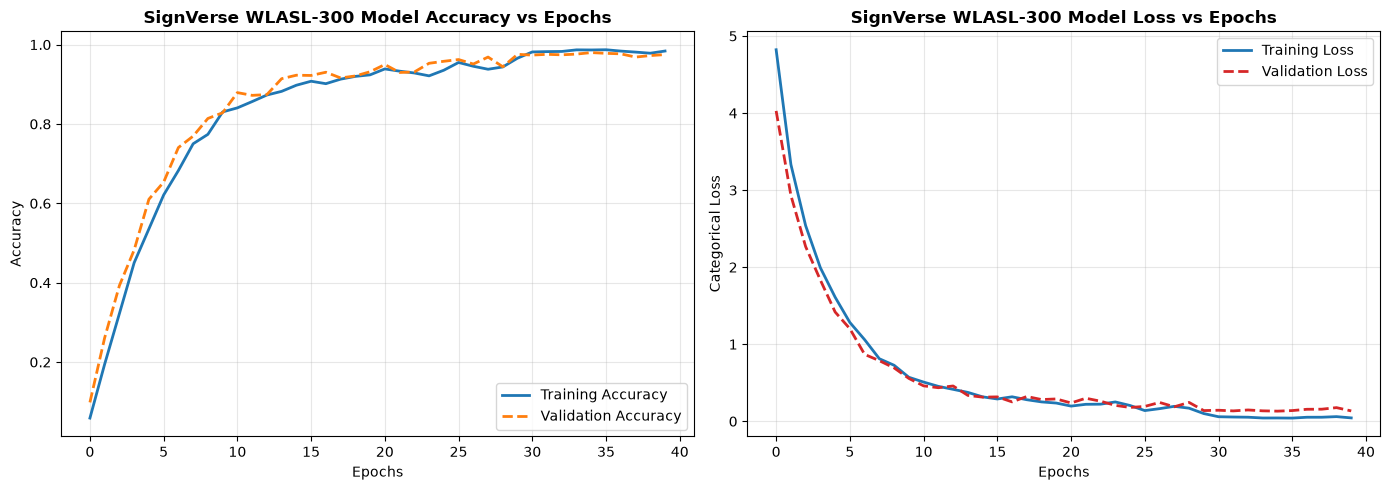

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("="*50)
print(f"WLASL-300 TEST SET ACCURACY: {test_acc * 100:.2f}%")
print(f"WLASL-300 TEST SET LOSS:     {test_loss:.4f}")
print("="*50)

# Plot Training & Validation Curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('SignVerse WLASL-300 Model Accuracy vs Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='#d62728', linewidth=2, linestyle='--')
plt.title('SignVerse WLASL-300 Model Loss vs Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Categorical Loss')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Real-Time Webcam Recognizer with Sentence Boundaries & Controls
### Interactive Controls:
- **`SPACE` Key**: Finalizes current sentence, auto-narrates via TTS, adds period (`.`), and starts a NEW sentence.
- **`C` Key**: Clears current sentence.
- **`S` Key**: Speaks active sentence out loud.
- **`Q` Key**: Exits live stream.
- **Auto-Pause Detection**: When no hands are detected for >2.0 seconds, it automatically marks sentence boundary!

In [12]:
class NotebookRealtimeSignRecognizer:
    def __init__(self, model_path="saved_models/best_signverse_model_300.keras", label_map=label_map):
        self.label_map = label_map
        self.extractor = NotebookMediaPipeLandmarkExtractor(static_image_mode=False)
        
        if os.path.exists(model_path):
            print(f"🧠 Loaded Trained Keras Model from '{model_path}'")
            self.model = tf.keras.models.load_model(model_path)
        else:
            print("⚠️ Model file not found, using current in-memory model!")
            self.model = model
            
        self.tts_engine = None
        if TTS_AVAILABLE:
            try:
                self.tts_engine = pyttsx3.init()
                self.tts_engine.setProperty('rate', 150)
            except Exception as e:
                print(f"⚠️ TTS initialization warning: {e}")

    def speak_text(self, text):
        print(f"🔊 Speaking sentence: '{text}'")
        if self.tts_engine:
            try:
                self.tts_engine.say(text)
                self.tts_engine.runAndWait()
            except Exception as e:
                print(f"⚠️ TTS error: {e}")

    def run_webcam_stream(self, sequence_length=30):
        cap = cv2.VideoCapture(0)
        if not cap.isOpened():
            print("❌ Unable to open webcam stream!")
            return

        print("\n" + "="*60)
        print("🎥 SignVerse Real-Time Sign Recognizer with Sentence Boundaries Started!")
        print("   - Press 'SPACE' : Finalize sentence & start NEW sentence")
        print("   - Press 'S'     : Read aloud active sentence")
        print("   - Press 'C'     : Clear current sentence")
        print("   - Press 'Q'     : Exit live window")
        print("="*60 + "\n")

        sequence_buffer = []
        current_words = []
        completed_sentences = []
        last_prediction = ""
        prediction_confidence = 0.0
        last_hand_time = time.time()

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
                
            frame = cv2.flip(frame, 1)
            feats, annotated_frame, detected_count = self.extractor.extract_landmarks(frame)
            
            if detected_count > 0:
                last_hand_time = time.time()
            else:
                if current_words and (time.time() - last_hand_time > 2.0):
                    sentence_str = " ".join(current_words) + "."
                    completed_sentences.append(sentence_str)
                    print(f"⏱️ Pause detected -> Auto Completed Sentence: '{sentence_str}'")
                    self.speak_text(sentence_str)
                    current_words.clear()
                    last_prediction = ""

            sequence_buffer.append(feats)
            if len(sequence_buffer) > sequence_length:
                sequence_buffer.pop(0)

            if len(sequence_buffer) == sequence_length and detected_count > 0:
                seq_input = np.array([sequence_buffer], dtype=np.float32)
                probs = self.model.predict(seq_input, verbose=0)[0]
                pred_idx = int(np.argmax(probs))
                prediction_confidence = float(probs[pred_idx])
                pred_word = self.label_map.get(pred_idx, "Unknown")
                
                if prediction_confidence > 0.65 and pred_word != last_prediction:
                    last_prediction = pred_word
                    if not current_words or current_words[-1] != pred_word:
                        current_words.append(pred_word)

            h, w = annotated_frame.shape[:2]
            cv2.rectangle(annotated_frame, (0, 0), (w, 85), (20, 20, 20), -1)
            cv2.putText(annotated_frame, "SignVerse - Live Sentence Recognition", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 255, 255), 2)
            
            conf_str = f"Live Sign: {last_prediction.upper()} ({prediction_confidence*100:.1f}%)" if last_prediction else "Waiting for gesture..."
            cv2.putText(annotated_frame, conf_str, (15, 65), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 225, 255), 1)

            cv2.rectangle(annotated_frame, (0, h - 80), (w, h), (15, 15, 30), -1)
            active_sentence = "Active Sentence: " + " ".join(current_words)
            cv2.putText(annotated_frame, active_sentence, (15, h - 45), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 150), 2)
            
            past_sentence_str = f"Last Finished: {completed_sentences[-1]}" if completed_sentences else "[SPACE: End Sentence & Next]"
            cv2.putText(annotated_frame, past_sentence_str, (15, h - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (180, 180, 180), 1)

            cv2.imshow("SignVerse - Live Sentence Recognizer", annotated_frame)
            
            key = cv2.waitKey(1) & 0xFF
            if key == ord('q') or key == 27:
                break
            elif key == 32:
                if current_words:
                    sentence_str = " ".join(current_words) + "."
                    completed_sentences.append(sentence_str)
                    print(f"📌 Manually Completed Sentence: '{sentence_str}'")
                    self.speak_text(sentence_str)
                    current_words.clear()
                    last_prediction = ""
            elif key == ord('s'):
                speech_text = " ".join(current_words) if current_words else "No sentence captured."
                self.speak_text(speech_text)
            elif key == ord('c'):
                current_words.clear()
                last_prediction = ""
                print("🧹 Active sentence cleared.")

        cap.release()
        cv2.destroyAllWindows()
        self.extractor.close()

recognizer = NotebookRealtimeSignRecognizer()
# Uncomment line below to launch webcam window:
recognizer.run_webcam_stream()


🧠 Loaded Trained Keras Model from 'saved_models/best_signverse_model_300.keras'

🎥 SignVerse Real-Time Sign Recognizer with Sentence Boundaries Started!
   - Press 'SPACE' : Finalize sentence & start NEW sentence
   - Press 'S'     : Read aloud active sentence
   - Press 'C'     : Clear current sentence
   - Press 'Q'     : Exit live window

📌 Manually Completed Sentence: 'ride dark plan stay catch walk party.'
🔊 Speaking sentence: 'ride dark plan stay catch walk party.'
🔊 Speaking sentence: 'No sentence captured.'
🔊 Speaking sentence: 'pizza walk same children'
⏱️ Pause detected -> Auto Completed Sentence: 'pizza walk same children.'
🔊 Speaking sentence: 'pizza walk same children.'
🔊 Speaking sentence: 'No sentence captured.'
🔊 Speaking sentence: 'No sentence captured.'
🔊 Speaking sentence: 'No sentence captured.'
🔊 Speaking sentence: 'No sentence captured.'
🔊 Speaking sentence: 'same catch'
📌 Manually Completed Sentence: 'same catch children.'
🔊 Speaking sentence: 'same catch childre

## 9. Enhanced 3D Avatar Skeleton Joint Animation Engine
Renders clear, realistic full-body & dual-hand skeleton joint structures (Shoulders, Elbows, Wrists, Palm & 5 Fingers per hand) with anatomical bone connections and gesture movement.

In [11]:
class NotebookTextToSign3DAvatarEngine:
    def __init__(self, dataset_dir="C:/Users/Rupa/Documents/SignVerse/DATASET_WLASL"):
        self.dataset_dir = dataset_dir
        self.wlasl_json = os.path.join(dataset_dir, "WLASL_v0.3.json")
        self.video_dir = os.path.join(dataset_dir, "videos")
        self.gloss_map = {}
        
        if os.path.exists(self.wlasl_json):
            with open(self.wlasl_json, 'r', encoding='utf-8') as f:
                data = json.load(f)
                for entry in data:
                    gloss = entry['gloss'].upper()
                    for inst in entry['instances']:
                        v_id = inst['video_id']
                        v_path = os.path.join(self.video_dir, f"{v_id}.mp4")
                        if os.path.exists(v_path):
                            self.gloss_map[gloss] = v_path
                            break

    def _draw_enhanced_skeleton_avatar(self, canvas, pts_vector, gloss_name, frame_num, total_frames):
        h, w = canvas.shape[:2]
        canvas.fill(20)
        
        cv2.rectangle(canvas, (0, 0), (w, 80), (35, 35, 35), -1)
        cv2.putText(canvas, f"SignVerse 3D Avatar -- Sign: {gloss_name.upper()}", (20, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (0, 220, 255), 2)
        cv2.putText(canvas, f"Frame {frame_num}/{total_frames} | Full Skeleton Joint Animation Engine", (20, 68), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (180, 180, 180), 1)
        
        head_center = (w // 2, 140)
        neck = (w // 2, 190)
        left_shoulder = (w // 2 - 90, 220)
        right_shoulder = (w // 2 + 90, 220)
        spine_base = (w // 2, 330)
        
        cv2.circle(canvas, head_center, 38, (0, 200, 255), 3)
        cv2.line(canvas, head_center, neck, (200, 200, 200), 4)
        cv2.line(canvas, left_shoulder, right_shoulder, (200, 200, 200), 5)
        cv2.line(canvas, neck, spine_base, (200, 200, 200), 4)
        
        connections = [
            (0,1),(1,2),(2,3),(3,4),
            (0,5),(5,6),(6,7),(7,8),
            (5,9),(9,10),(10,11),(11,12),
            (9,13),(13,14),(14,15),(15,16),
            (13,17),(17,18),(18,19),(19,20),(0,17)
        ]
        
        left_pts = pts_vector[0:63].reshape((21, 3))
        if np.any(left_pts):
            l_wrist_px = (int(left_shoulder[0] + left_pts[0,0]*150), int(left_shoulder[1] + 80 + left_pts[0,1]*150))
            cv2.line(canvas, left_shoulder, l_wrist_px, (100, 255, 100), 4)
            
            l_px_list = []
            for pt in left_pts:
                px = (int(l_wrist_px[0] + pt[0]*120), int(l_wrist_px[1] + pt[1]*120))
                l_px_list.append(px)
                cv2.circle(canvas, px, 4, (0, 255, 0), -1)
                
            for p1, p2 in connections:
                cv2.line(canvas, l_px_list[p1], l_px_list[p2], (50, 200, 50), 2)
                
        right_pts = pts_vector[63:126].reshape((21, 3))
        if np.any(right_pts):
            r_wrist_px = (int(right_shoulder[0] + right_pts[0,0]*150), int(right_shoulder[1] + 80 + right_pts[0,1]*150))
            cv2.line(canvas, right_shoulder, r_wrist_px, (255, 150, 100), 4)
            
            r_px_list = []
            for pt in right_pts:
                px = (int(r_wrist_px[0] + pt[0]*120), int(r_wrist_px[1] + pt[1]*120))
                r_px_list.append(px)
                cv2.circle(canvas, px, 4, (255, 100, 0), -1)
                
            for p1, p2 in connections:
                cv2.line(canvas, r_px_list[p1], r_px_list[p2], (220, 100, 0), 2)
                
        cv2.rectangle(canvas, (0, h - 45), (w, h), (30, 30, 30), -1)
        cv2.putText(canvas, "Press SPACE / ENTER for next sign word | Press 'Q' to exit", (20, h - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (200, 200, 200), 1)
        return canvas

    def render_3d_avatar_gestures(self, text):
        words = [w.strip().upper() for w in text.split() if w.strip()]
        print(f"\n🤟 Translating Text into 3D Animated Avatar Gestures: '{text}'")
        
        extractor = NotebookMediaPipeLandmarkExtractor(static_image_mode=False)
        cv2.namedWindow("SignVerse - 3D Avatar Sign Translator", cv2.WINDOW_AUTOSIZE)
        
        for word in words:
            v_path = self.gloss_map.get(word)
            if not v_path:
                print(f"   ⚠️ Word '{word}' not in dataset video index.")
                continue
                
            cap = cv2.VideoCapture(v_path)
            frames_data = []
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break
                vector, _, _ = extractor.extract_landmarks(frame)
                frames_data.append(vector)
            cap.release()
            
            if not frames_data:
                continue
                
            total_frames = len(frames_data)
            canvas = np.zeros((600, 800, 3), dtype=np.uint8)
            
            for i, pts in enumerate(frames_data):
                frame_img = self._draw_enhanced_skeleton_avatar(canvas.copy(), pts, word, i+1, total_frames)
                cv2.imshow("SignVerse - 3D Avatar Sign Translator", frame_img)
                key = cv2.waitKey(40) & 0xFF
                if key == ord('q'):
                    cv2.destroyAllWindows()
                    extractor.close()
                    return
            time.sleep(0.4)
            
        cv2.destroyAllWindows()
        extractor.close()
        print("[OK] 3D Avatar Gesture Rendering Finished!")

avatar_engine = NotebookTextToSign3DAvatarEngine()
avatar_engine.render_3d_avatar_gestures("hello doctor please help computer")



🤟 Translating Text into 3D Animated Avatar Gestures: 'hello doctor please help computer'
[OK] 3D Avatar Gesture Rendering Finished!
